# 2D Chebyshev interpolation

In higher dimensions the workflow is the same, but three orderings must agree:

1. **Array axes ↔ variables.** The values must be sampled on the **tensor
   grid** of per-axis Chebyshev nodes, built with
   `np.meshgrid(..., indexing='ij')` so that `vals[i, j]` corresponds to
   `(x_i, y_j)`. NumPy's default `indexing='xy'` swaps the two axes.
2. **Bounds per axis, in axis order.** The constructor takes `ax, bx` for axis
   0 (x), then `ay, by` for axis 1 (y) — one (lower, upper) pair per axis, not
   all the lower bounds first. Passing them by keyword avoids mix-ups.
3. **The same bounds for nodes and interpolant**, with the nodes sampled in
   the order `chebyshev_nodes` returns them.

This notebook deliberately uses a **different number of nodes and a different
domain on each axis**. On a square grid with equal domains, ordering mistakes
raise no error and just give a wrong interpolant — the last section shows
how. A single 2D DCT then produces all coefficients at once.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from chebyshevnd import ChebyshevInterpolant2D, chebyshev_nodes

In [2]:
f = lambda x, y: np.exp(-(x**2 + y**2) / 2) * np.cos(2 * x + y)
ax_, bx_ = -2.0, 2.0   # bounds of x (axis 0)
ay_, by_ = -1.0, 3.0   # bounds of y (axis 1)
Nx, Ny = 40, 28        # different node counts make axis mix-ups visible

x_nodes = chebyshev_nodes(Nx, ax_, bx_)
y_nodes = chebyshev_nodes(Ny, ay_, by_)
X, Y = np.meshgrid(x_nodes, y_nodes, indexing="ij")
vals = f(X, Y)
print("vals.shape:", vals.shape)   # (Nx, Ny): axis 0 is x, axis 1 is y

interp = ChebyshevInterpolant2D(vals, ax=ax_, bx=bx_, ay=ay_, by=by_)

vals.shape: (40, 28)


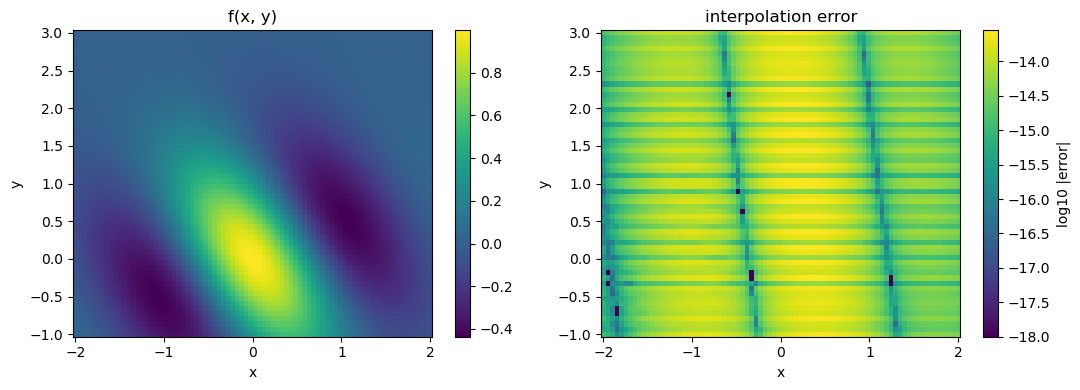

max error on the test grid: 2.831e-14
estimated absolute error:   5.444e-12


In [3]:
# Evaluate on an equally spaced test grid and compare with the true function
xt = np.linspace(ax_, bx_, 80)
yt = np.linspace(ay_, by_, 60)
Z_true = f(*np.meshgrid(xt, yt, indexing="ij"))
Z_interp = np.array([[interp.evaluate(x, y) for y in yt] for x in xt])
err = np.abs(Z_interp - Z_true)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
im1 = ax1.pcolormesh(xt, yt, Z_true.T, shading="auto")
fig.colorbar(im1, ax=ax1)
ax1.set_title("f(x, y)")
im2 = ax2.pcolormesh(xt, yt, np.log10(err.T + 1e-18), shading="auto")
fig.colorbar(im2, ax=ax2, label="log10 |error|")
ax2.set_title("interpolation error")
for axis in (ax1, ax2):
    axis.set_xlabel("x")
    axis.set_ylabel("y")
plt.tight_layout()
plt.show()

print(f"max error on the test grid: {err.max():.3e}")
print(f"estimated absolute error:   {interp.absolute_error():.3e}")

## Coefficient structure

The coefficient matrix decays away from the (0, 0) corner; how fast it decays
along each axis is what the truncation machinery exploits.

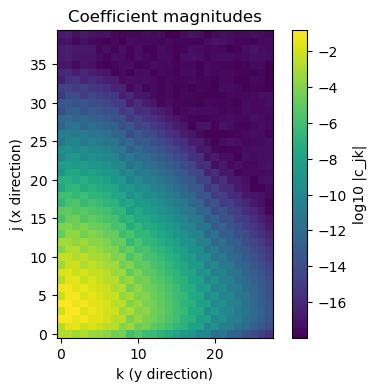

In [4]:
plt.figure(figsize=(5, 4))
plt.imshow(np.log10(np.abs(interp.get_coefficients()) + 1e-18), origin="lower")
plt.colorbar(label="log10 |c_jk|")
plt.xlabel("k (y direction)")
plt.ylabel("j (x direction)")
plt.title("Coefficient magnitudes")
plt.show()

## Truncating with `optimize`

`optimize(rel_tol)` computes per-row truncation counts, so rows whose
coefficients decay quickly use shorter Clenshaw recursions. `effective_grid()`
reports the reduced sizes.

In [5]:
print(f"full grid:      {[Nx, Ny]}")
interp.optimize(rel_tol=1e-10)
print(f"effective grid: {interp.effective_grid()}")

Z_opt = np.array([[interp.evaluate(x, y) for y in yt] for x in xt])
print(f"max error after truncation: {np.max(np.abs(Z_opt - Z_true)):.3e}")

full grid:      [40, 28]
effective grid: [31, 28]
max error after truncation: 1.171e-13


## Pitfalls: ordering mistakes

Two common mistakes, and what they do on this non-square grid. Neither raises
an error; both show up immediately when the interpolant is compared with the
function at a few random points.

In [6]:
rng = np.random.default_rng(0)
test_points = [(rng.uniform(ax_, bx_), rng.uniform(ay_, by_)) for _ in range(200)]

def max_error(itp):
    return max(abs(itp.evaluate(x, y) - f(x, y)) for x, y in test_points)

# 1. Bounds grouped as (all lower, all upper) instead of one pair per axis
wrong_bounds = ChebyshevInterpolant2D(vals, ax_, ay_, bx_, by_)

# 2. meshgrid's default indexing='xy' swaps the axes of the value array
Xw, Yw = np.meshgrid(x_nodes, y_nodes)
vals_xy = f(Xw, Yw)
wrong_indexing = ChebyshevInterpolant2D(vals_xy, ax=ax_, bx=bx_, ay=ay_, by=by_)

print(f"correct:                    max error {max_error(interp):.1e}")
print(f"bounds as (ax, ay, bx, by): max error {max_error(wrong_bounds):.1e}")
print(f"indexing='xy':              max error {max_error(wrong_indexing):.1e}"
      f"  (vals.shape {vals_xy.shape}, expected {vals.shape})")

correct:                    max error 1.2e-13
bounds as (ax, ay, bx, by): max error 1.7e+55
indexing='xy':              max error 9.1e-01  (vals.shape (28, 40), expected (40, 28))


On a **square grid with the same domain on both axes**, the `indexing='xy'`
mistake is invisible: the shape looks right and nothing fails, but the
interpolant silently represents $f(y, x)$ instead of $f(x, y)$. This is why
the examples use a different number of nodes and a different domain per
axis, and why you should test your own setup the same way.

In [7]:
s_nodes = chebyshev_nodes(30, -2.0, 2.0)
Xs, Ys = np.meshgrid(s_nodes, s_nodes)    # default indexing='xy' again
square = ChebyshevInterpolant2D(f(Xs, Ys), ax=-2.0, bx=2.0, ay=-2.0, by=2.0)

print("vals.shape:", f(Xs, Ys).shape, "- looks fine")
print(f"interpolant at (0.3, -1.1): {square.evaluate(0.3, -1.1):+.6f}")
print(f"f(0.3, -1.1):               {f(0.3, -1.1):+.6f}")
print(f"f(-1.1, 0.3):               {f(-1.1, 0.3):+.6f}   <- what it actually returns")

vals.shape: (30, 30) - looks fine
interpolant at (0.3, -1.1): -0.168772
f(0.3, -1.1):               +0.458138
f(-1.1, 0.3):               -0.168772   <- what it actually returns
